# Exploratory Data Analysis

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

from utils import *

## Load Data
Load data and select features with an SQL query through the duckdb.

In [2]:
""" 
Adjust list based on the features considered.
Knowing what columns to include is based on domain knowledge of League of Legends Esports.
Refer to the original source database by Oracke's Elixir by Tim Sevenhuysen.
"""
cols_to_include = ['gameid', 'league', 'year', 'split', 'patch',
                   'teamname', 'gamelength', 'result', 'kills',
                   'deaths', 'assists', 'towers', 'dpm', 'damagetakenperminute',
                   'wardskilled', 'totalgold', 'goldspent',
                   'firstdragon', 'firstbaron', 'barons', 'opp_barons',
                   'golddiffat10', 'xpdiffat10', 'killsat10', 'assistsat10', 'opp_killsat10', 'opp_deathsat10',
                   'golddiffat15', 'xpdiffat15', 'killsat15', 'assistsat15', 'opp_killsat15', 'opp_deathsat15',
                   'golddiffat20', 'xpdiffat20', 'killsat20', 'assistsat20', 'opp_killsat20', 'opp_deathsat20',
                   'golddiffat25', 'xpdiffat25', 'killsat25', 'assistsat25', 'opp_killsat25', 'opp_deathsat25'
                   ]

db = 'lol_predictors.duckdb'
df_selected = "df_2026" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include, db)

### Data Overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19506 entries, 0 to 19505
Data columns (total 45 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gameid                19506 non-null  str    
 1   league                19506 non-null  str    
 2   year                  19506 non-null  int64  
 3   split                 16220 non-null  str    
 4   patch                 19506 non-null  float64
 5   teamname              19506 non-null  str    
 6   gamelength            19506 non-null  int64  
 7   result                19506 non-null  int64  
 8   kills                 19506 non-null  int64  
 9   deaths                19506 non-null  int64  
 10  assists               19506 non-null  int64  
 11  towers                19506 non-null  float64
 12  dpm                   19506 non-null  float64
 13  damagetakenperminute  19506 non-null  float64
 14  wardskilled           19506 non-null  int64  
 15  totalgold             19506 no

In [4]:
df.shape

(19506, 45)

In [5]:
df.describe()

,year,patch,gamelength,result,kills,deaths,assists,towers,dpm,damagetakenperminute,...,killsat20,assistsat20,opp_killsat20,opp_deathsat20,golddiffat25,xpdiffat25,killsat25,assistsat25,opp_killsat25,opp_deathsat25
count,19506.000000,19506.000000,19506.000000,19506.000000,19506.000000,19506.000000,19506.000000,19506.000000,19506.000000,19506.000000,...,19106.000000,19106.000000,19106.000000,19106.000000,17770.00000,17770.000000,17770.000000,17770.000000,17770.000000,17770.000000
mean,2026.015893,16.101002,1883.805188,0.500000,16.592689,16.625038,35.679022,5.909618,2892.256436,3737.309874,...,7.907045,13.778761,7.907045,7.927039,0.00000,0.000000,10.944738,21.437310,10.944738,10.967136
std,0.127499,0.055685,331.238451,0.500013,8.262450,8.262458,19.079546,3.676384,684.056340,654.243102,...,4.817240,8.794427,4.817240,4.823676,6885.83803,7408.069896,6.062182,12.570312,6.062182,6.067337
min,2025.000000,15.240000,1000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,868.534200,1805.081400,...,0.000000,0.000000,0.000000,0.000000,-22049.00000,-22919.000000,0.000000,0.000000,0.000000,0.000000
25%,2026.000000,16.060000,1642.000000,0.000000,10.000000,10.000000,20.000000,2.000000,2407.976675,3289.286825,...,4.000000,7.000000,4.000000,4.000000,-4726.25000,-5331.750000,6.000000,12.000000,6.000000,7.000000
50%,2026.000000,16.100000,1855.000000,0.500000,16.000000,16.000000,35.000000,7.000000,2860.006850,3698.511300,...,7.000000,12.000000,7.000000,7.000000,0.00000,0.000000,10.000000,19.000000,10.000000,10.000000
75%,2026.000000,16.150000,2080.000000,1.000000,22.000000,22.000000,49.000000,9.000000,3335.889225,4141.546175,...,10.000000,19.000000,10.000000,10.000000,4726.25000,5331.750000,14.000000,29.000000,14.000000,14.000000
max,2027.000000,16.200000,3657.000000,1.000000,54.000000,54.000000,122.000000,18.000000,6677.577400,7449.984500,...,53.000000,73.000000,53.000000,53.000000,22049.00000,22919.000000,52.000000,88.000000,52.000000,52.000000


## Data Audit

In [6]:
# Limit numerical columns for description and visualization
numcols_to_drop = ['year', 'patch', 'result', 'towers', 'firstbaron', 'firstdragon']

# Limit categorical columns for description and visualization
catcols_to_drop = ['gameid', 'teamname']

In [7]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'year', 'split', 'patch', 'teamname', 'gamelength',
       'result', 'kills', 'deaths', 'assists', 'towers', 'dpm',
       'damagetakenperminute', 'wardskilled', 'totalgold', 'goldspent',
       'firstdragon', 'firstbaron', 'barons', 'opp_barons', 'golddiffat10',
       'xpdiffat10', 'killsat10', 'assistsat10', 'opp_killsat10',
       'opp_deathsat10', 'golddiffat15', 'xpdiffat15', 'killsat15',
       'assistsat15', 'opp_killsat15', 'opp_deathsat15', 'golddiffat20',
       'xpdiffat20', 'killsat20', 'assistsat20', 'opp_killsat20',
       'opp_deathsat20', 'golddiffat25', 'xpdiffat25', 'killsat25',
       'assistsat25', 'opp_killsat25', 'opp_deathsat25'],
      dtype='str')

------------ COUNT OF MISSING VALUES -------------


gameid                     0
league                     0
year                       0
split                   3286
patch                      0
teamname                   0
gamelength                 0
result                     0
kills                      0
deaths                     0
assists                    0
towers                     0
dpm                        0
damagetakenperminute       0
wardskilled                0
totalgold                  0
goldspent                 12
firstdragon               20
firstbaron               474
barons                     0
opp_barons                 0
golddiffat10             350
xpdiffat10               350
killsat10                350
assistsat10              350
opp_killsat10            350
opp_deathsat10           350
golddiffat15             348
xpdiffat15               348
killsat15                348
assistsat15              348
opp_killsat15            348
opp_deathsat15           348
golddiffat20             400
xpdiffat20    


------------- COUNT OF UNIQUE VALUES -------------


gameid                   9753
league                     44
year                        3
split                      17
patch                      20
teamname                  415
gamelength               1523
result                      2
kills                      54
deaths                     54
assists                   108
towers                     18
dpm                     19490
damagetakenperminute    19492
wardskilled               120
totalgold               15642
goldspent               12765
firstdragon                 2
firstbaron                  2
barons                      5
opp_barons                  5
golddiffat10             6227
xpdiffat10               4973
killsat10                  18
assistsat10                26
opp_killsat10              18
opp_deathsat10             18
golddiffat15             9507
xpdiffat15               8551
killsat15                  30
assistsat15                41
opp_killsat15              30
opp_deathsat15             30
golddiffat


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
LPL          1348
EM           1038
LAS          1020
LCK          1004
LCKC          982
LEC           766
LJL           726
AL            700
PRM           644
CBLOL         598
LCP           566
LCS           566
NACL          562
LIT           560
LFL           550
ROL           522
CD            516
HLL           470
EWC           464
TCL           438
EBL           426
RL            422
NLC           420
LES           416
HC            402
LRS           374
LRN           352
HM            348
LPLOL         324
VCS           310
NL            298
HW            206
PCS           172
WSCI          170
MSI           142
DCGI          142
AM            126
KeSPA Cup     122
FST            90
CCWS           80
WLDs           68
AC             38
WLRQ           12
DCup            6
Name: count, dtype: int64

 split
Summer        3660
Spring        3592
Winter        1806
Split 2       1438
Split 1       1390
Rounds 1-2     890

In [8]:
count_outliers(df, numcols_to_drop)


--------------- COUNT OF OUTLIERS ----------------
gamelength:               286 (1.47%)
kills:                     66 (0.34%)
deaths:                    66 (0.34%)
assists:                   43 (0.22%)
dpm:                      148 (0.76%)
damagetakenperminute:     239 (1.23%)
wardskilled:              249 (1.28%)
totalgold:                233 (1.19%)
goldspent:                303 (1.55%)
barons:                   224 (1.15%)
opp_barons:               224 (1.15%)
golddiffat10:             364 (1.87%)
xpdiffat10:               394 (2.02%)
killsat10:                323 (1.66%)
assistsat10:              664 (3.40%)
opp_killsat10:            323 (1.66%)
opp_deathsat10:           326 (1.67%)
golddiffat15:             504 (2.58%)
xpdiffat15:               386 (1.98%)
killsat15:                446 (2.29%)
assistsat15:              457 (2.34%)
opp_killsat15:            446 (2.29%)
opp_deathsat15:           453 (2.32%)
golddiffat20:             294 (1.51%)
xpdiffat20:               316 (1.62%

# Data Visualisation

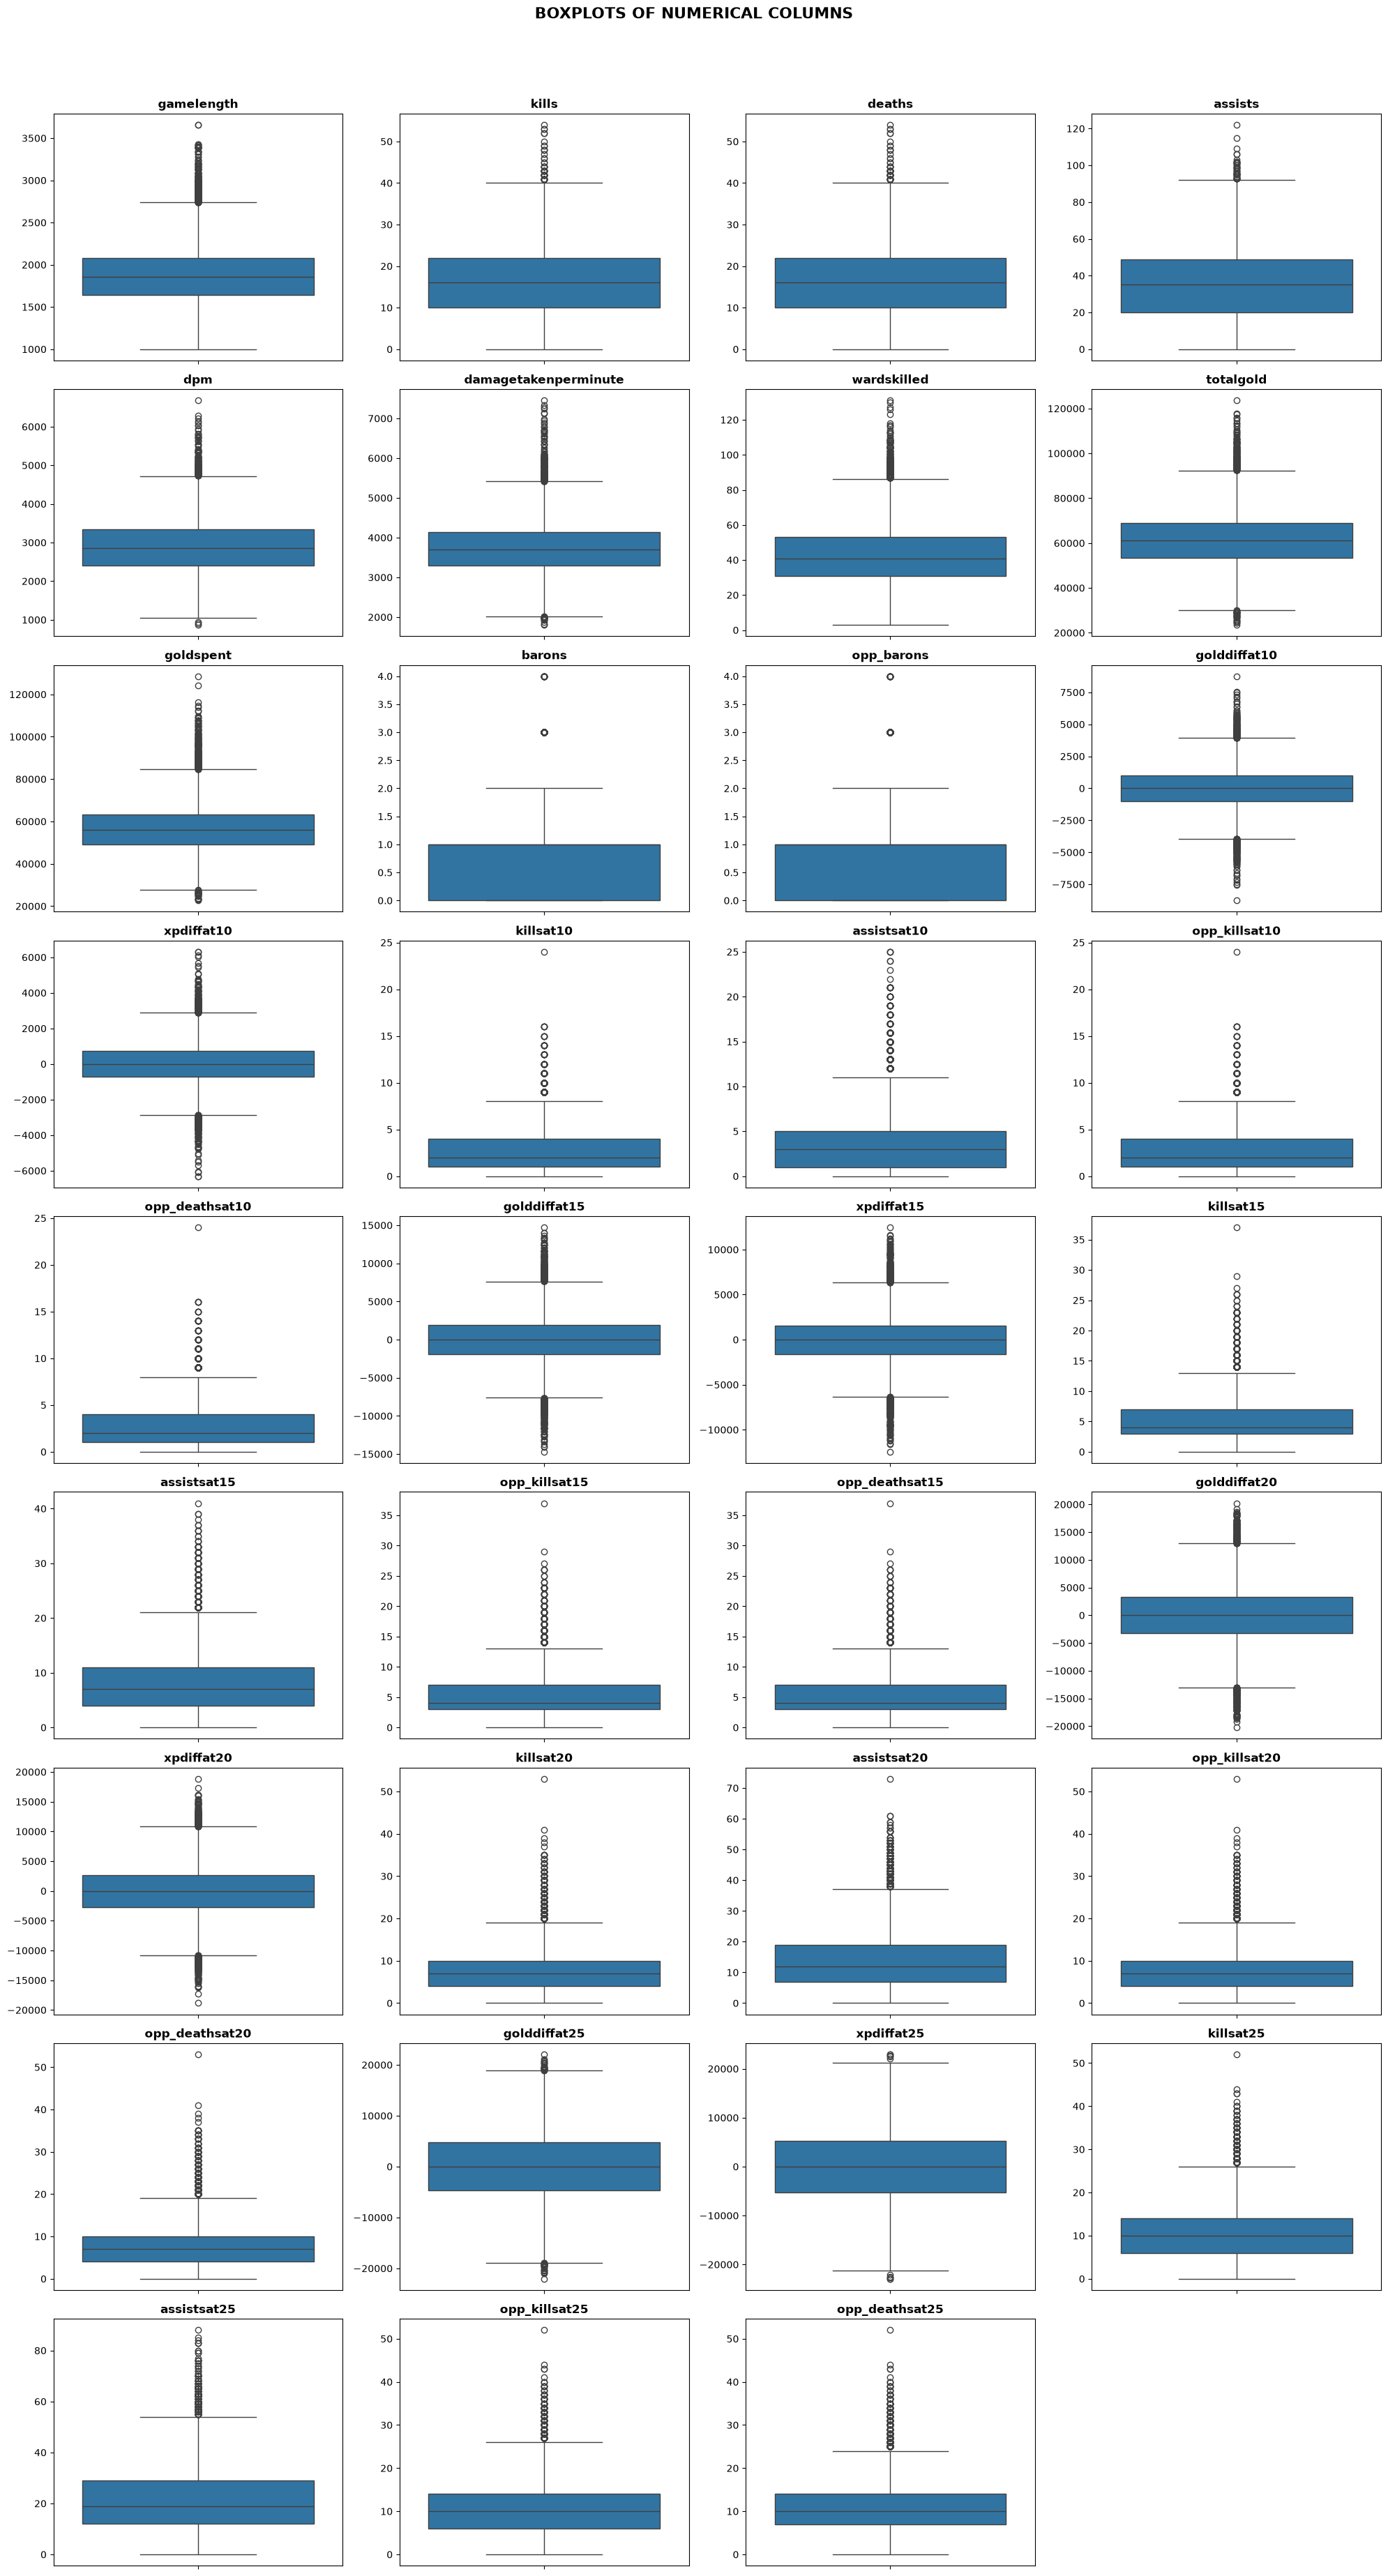

In [9]:
visualize_outliers(df, numcols_to_drop, nrows=10, ncols=4, figsize=(20, 40))

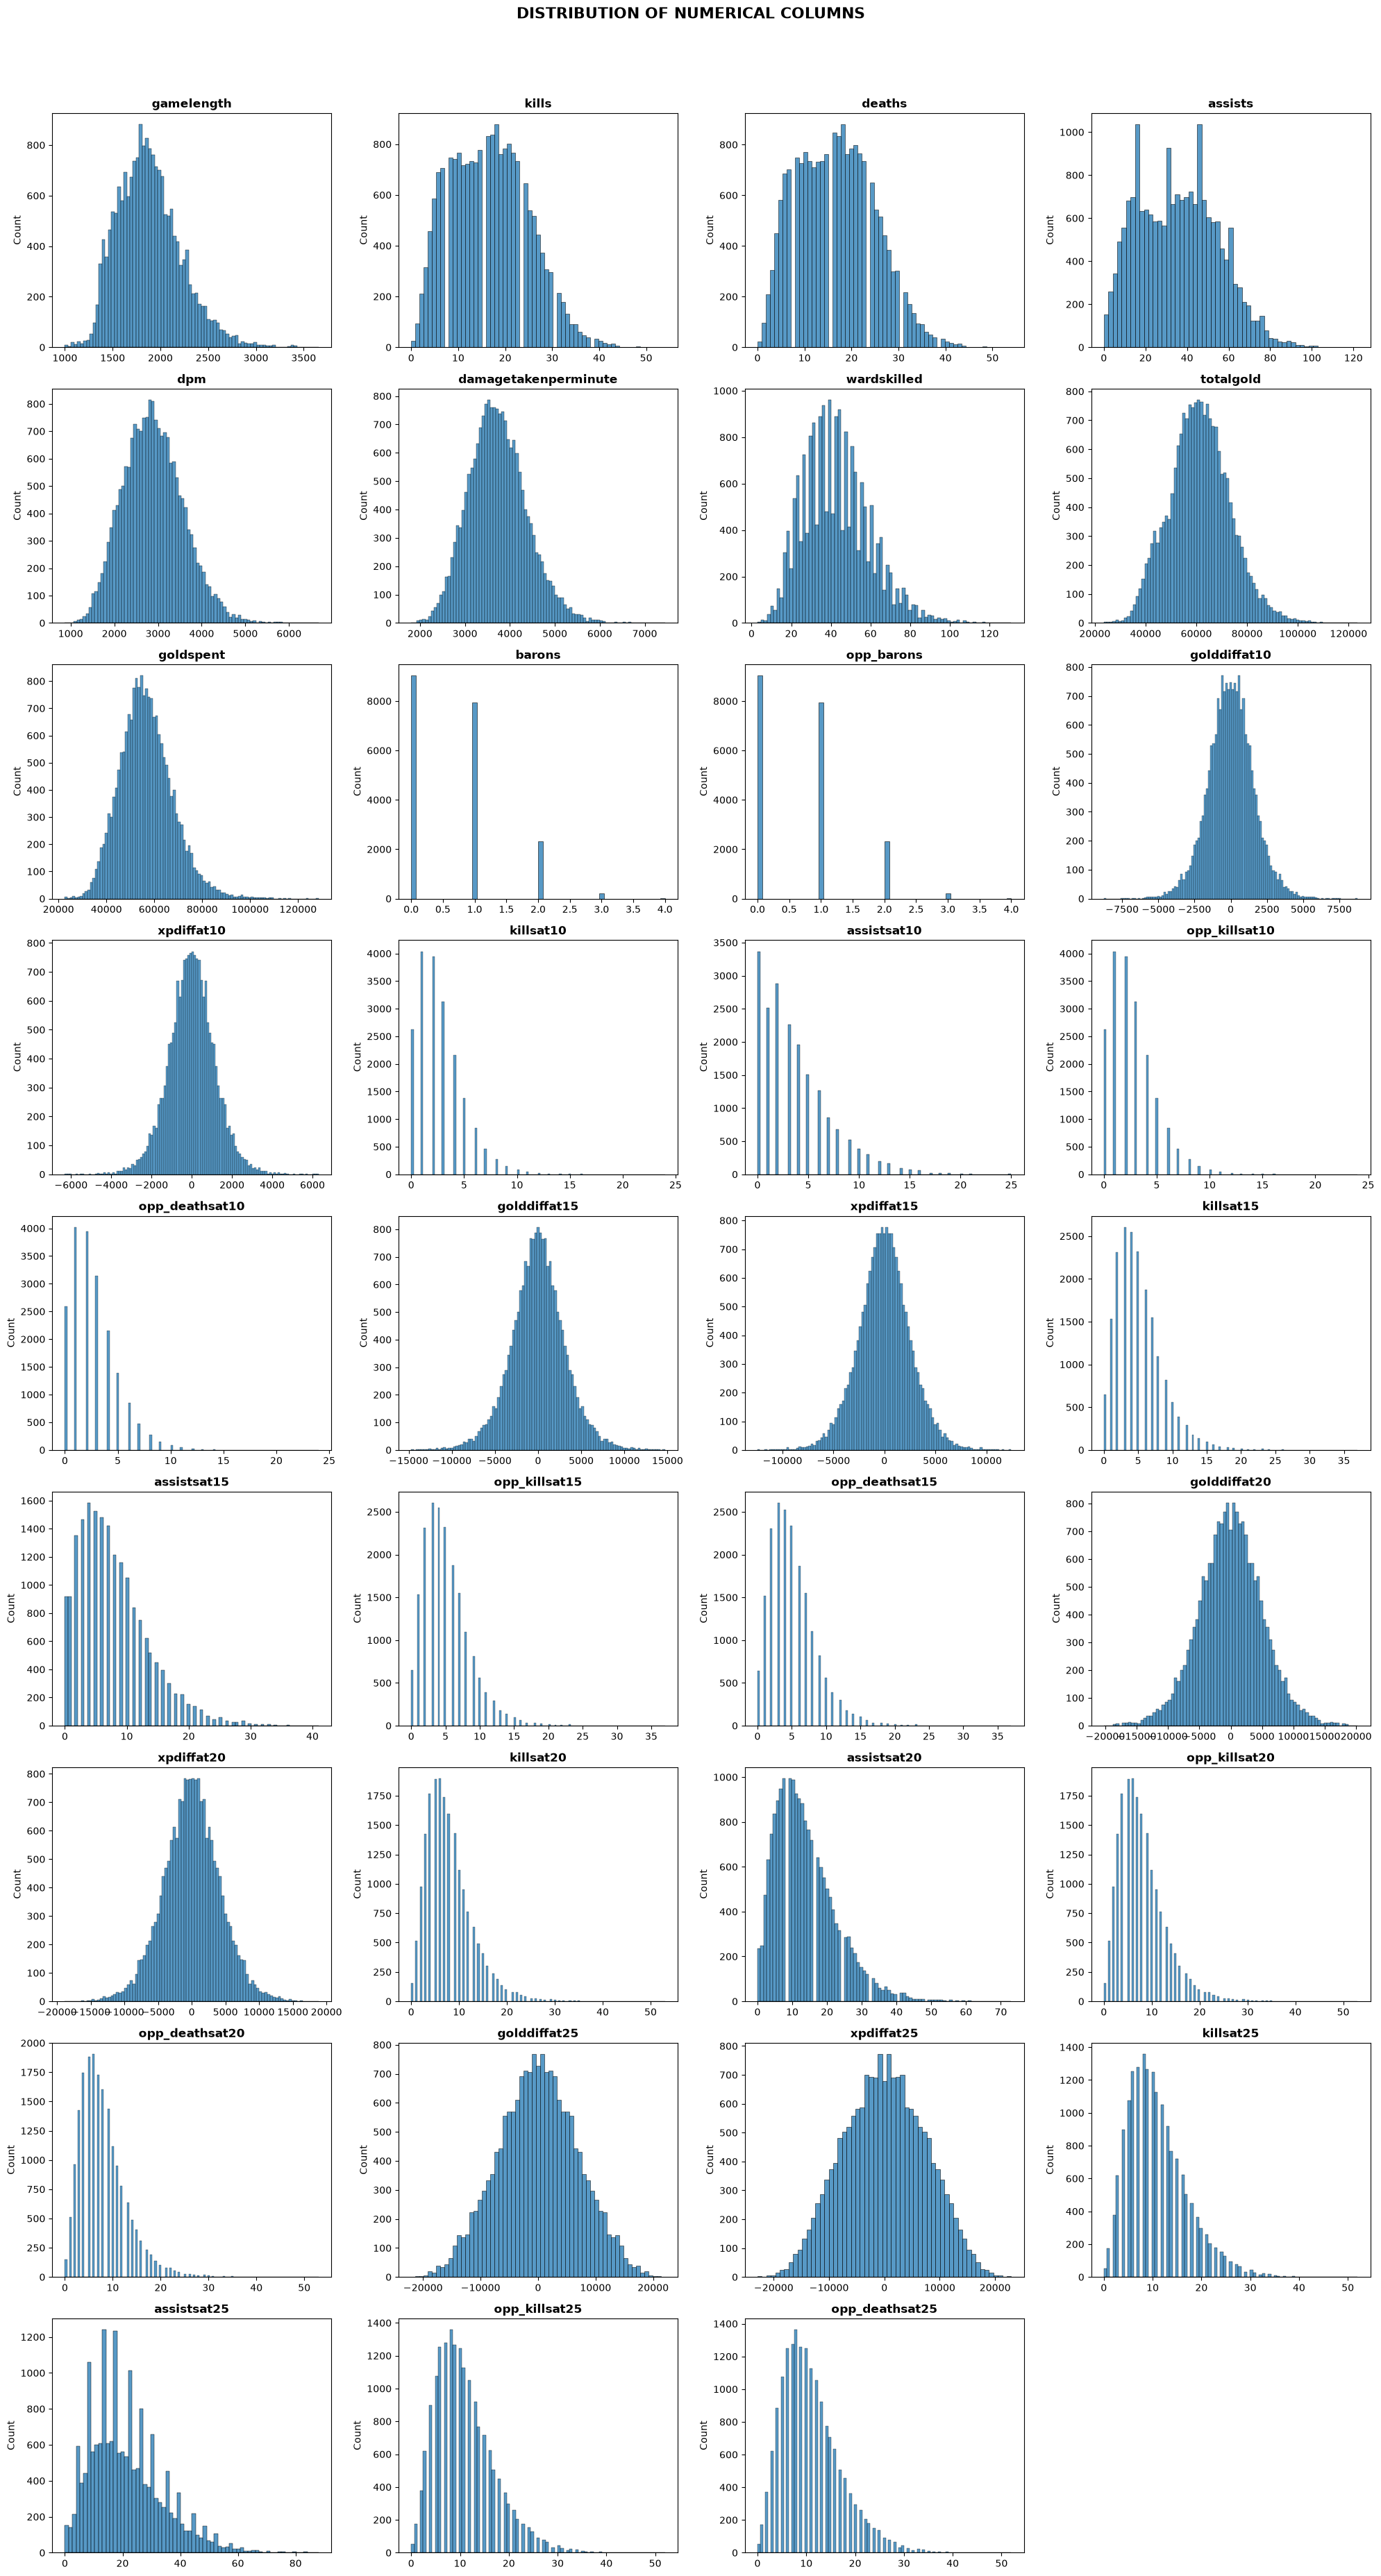

In [10]:
visualize_num_distribution(df, numcols_to_drop, nrows=10, ncols=4, figsize=(20, 40))

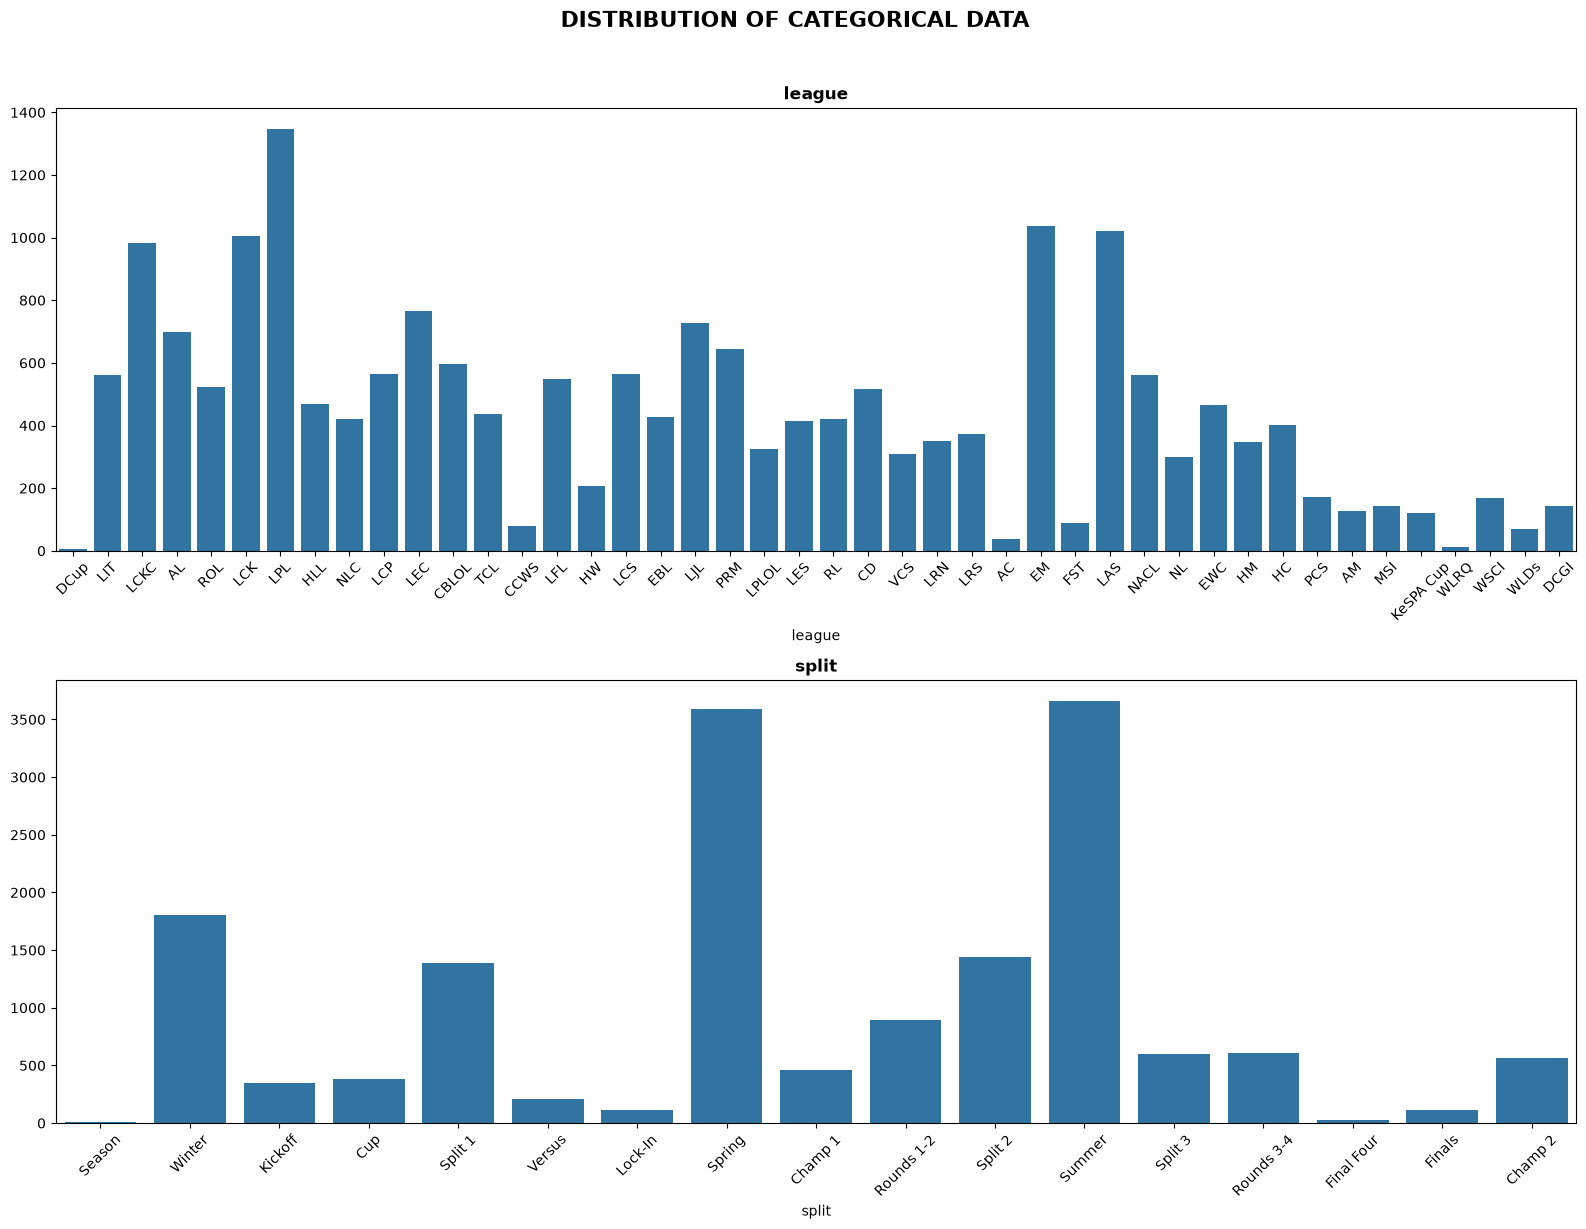

In [14]:
visualize_cat_distribution(df, catcols_to_drop, nrows=2, ncols=1)

c:\Users\ADMIN\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25105 (\N{CJK UNIFIED IDEOGRAPH-6211}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\ADMIN\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 36229 (\N{CJK UNIFIED IDEOGRAPH-8D85}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\ADMIN\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23041 (\N{CJK UNIFIED IDEOGRAPH-5A01}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\ADMIN\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\ADMIN\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29228 (\N{CJK UNIFIED IDEOGRAPH-722C}) missing from font(s) DejaVu San

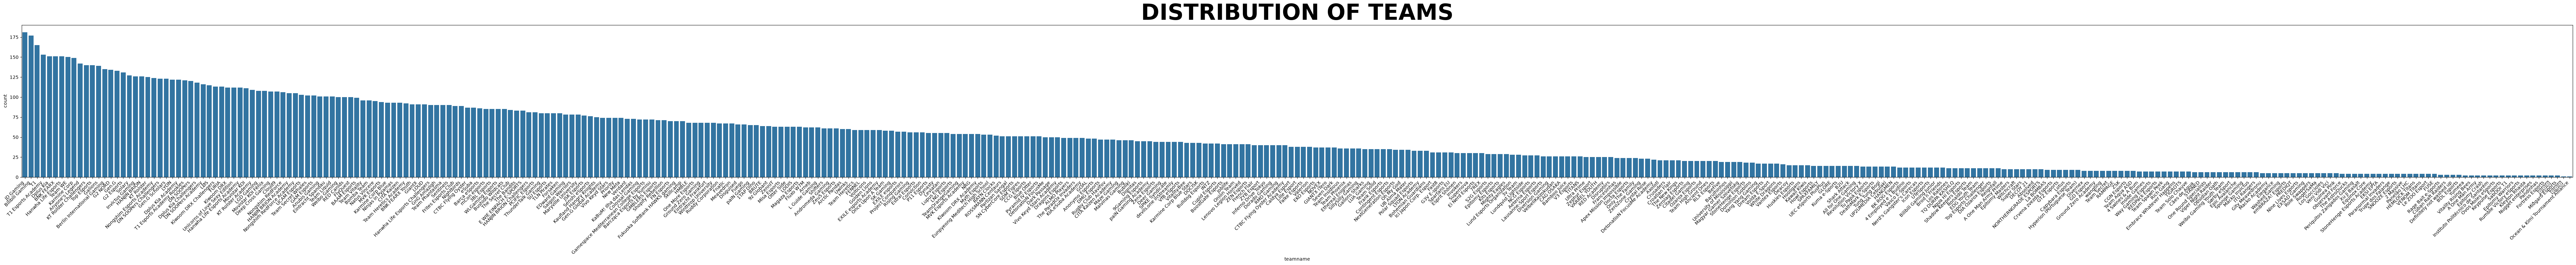

In [ ]:
# Separate visualization for team names distribution
team_order = df["teamname"].value_counts().index
plt.figure(figsize=(100, 6))
sns.countplot(data=df, x='teamname', order=team_order)
plt.title('DISTRIBUTION OF TEAMS', fontsize=48, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

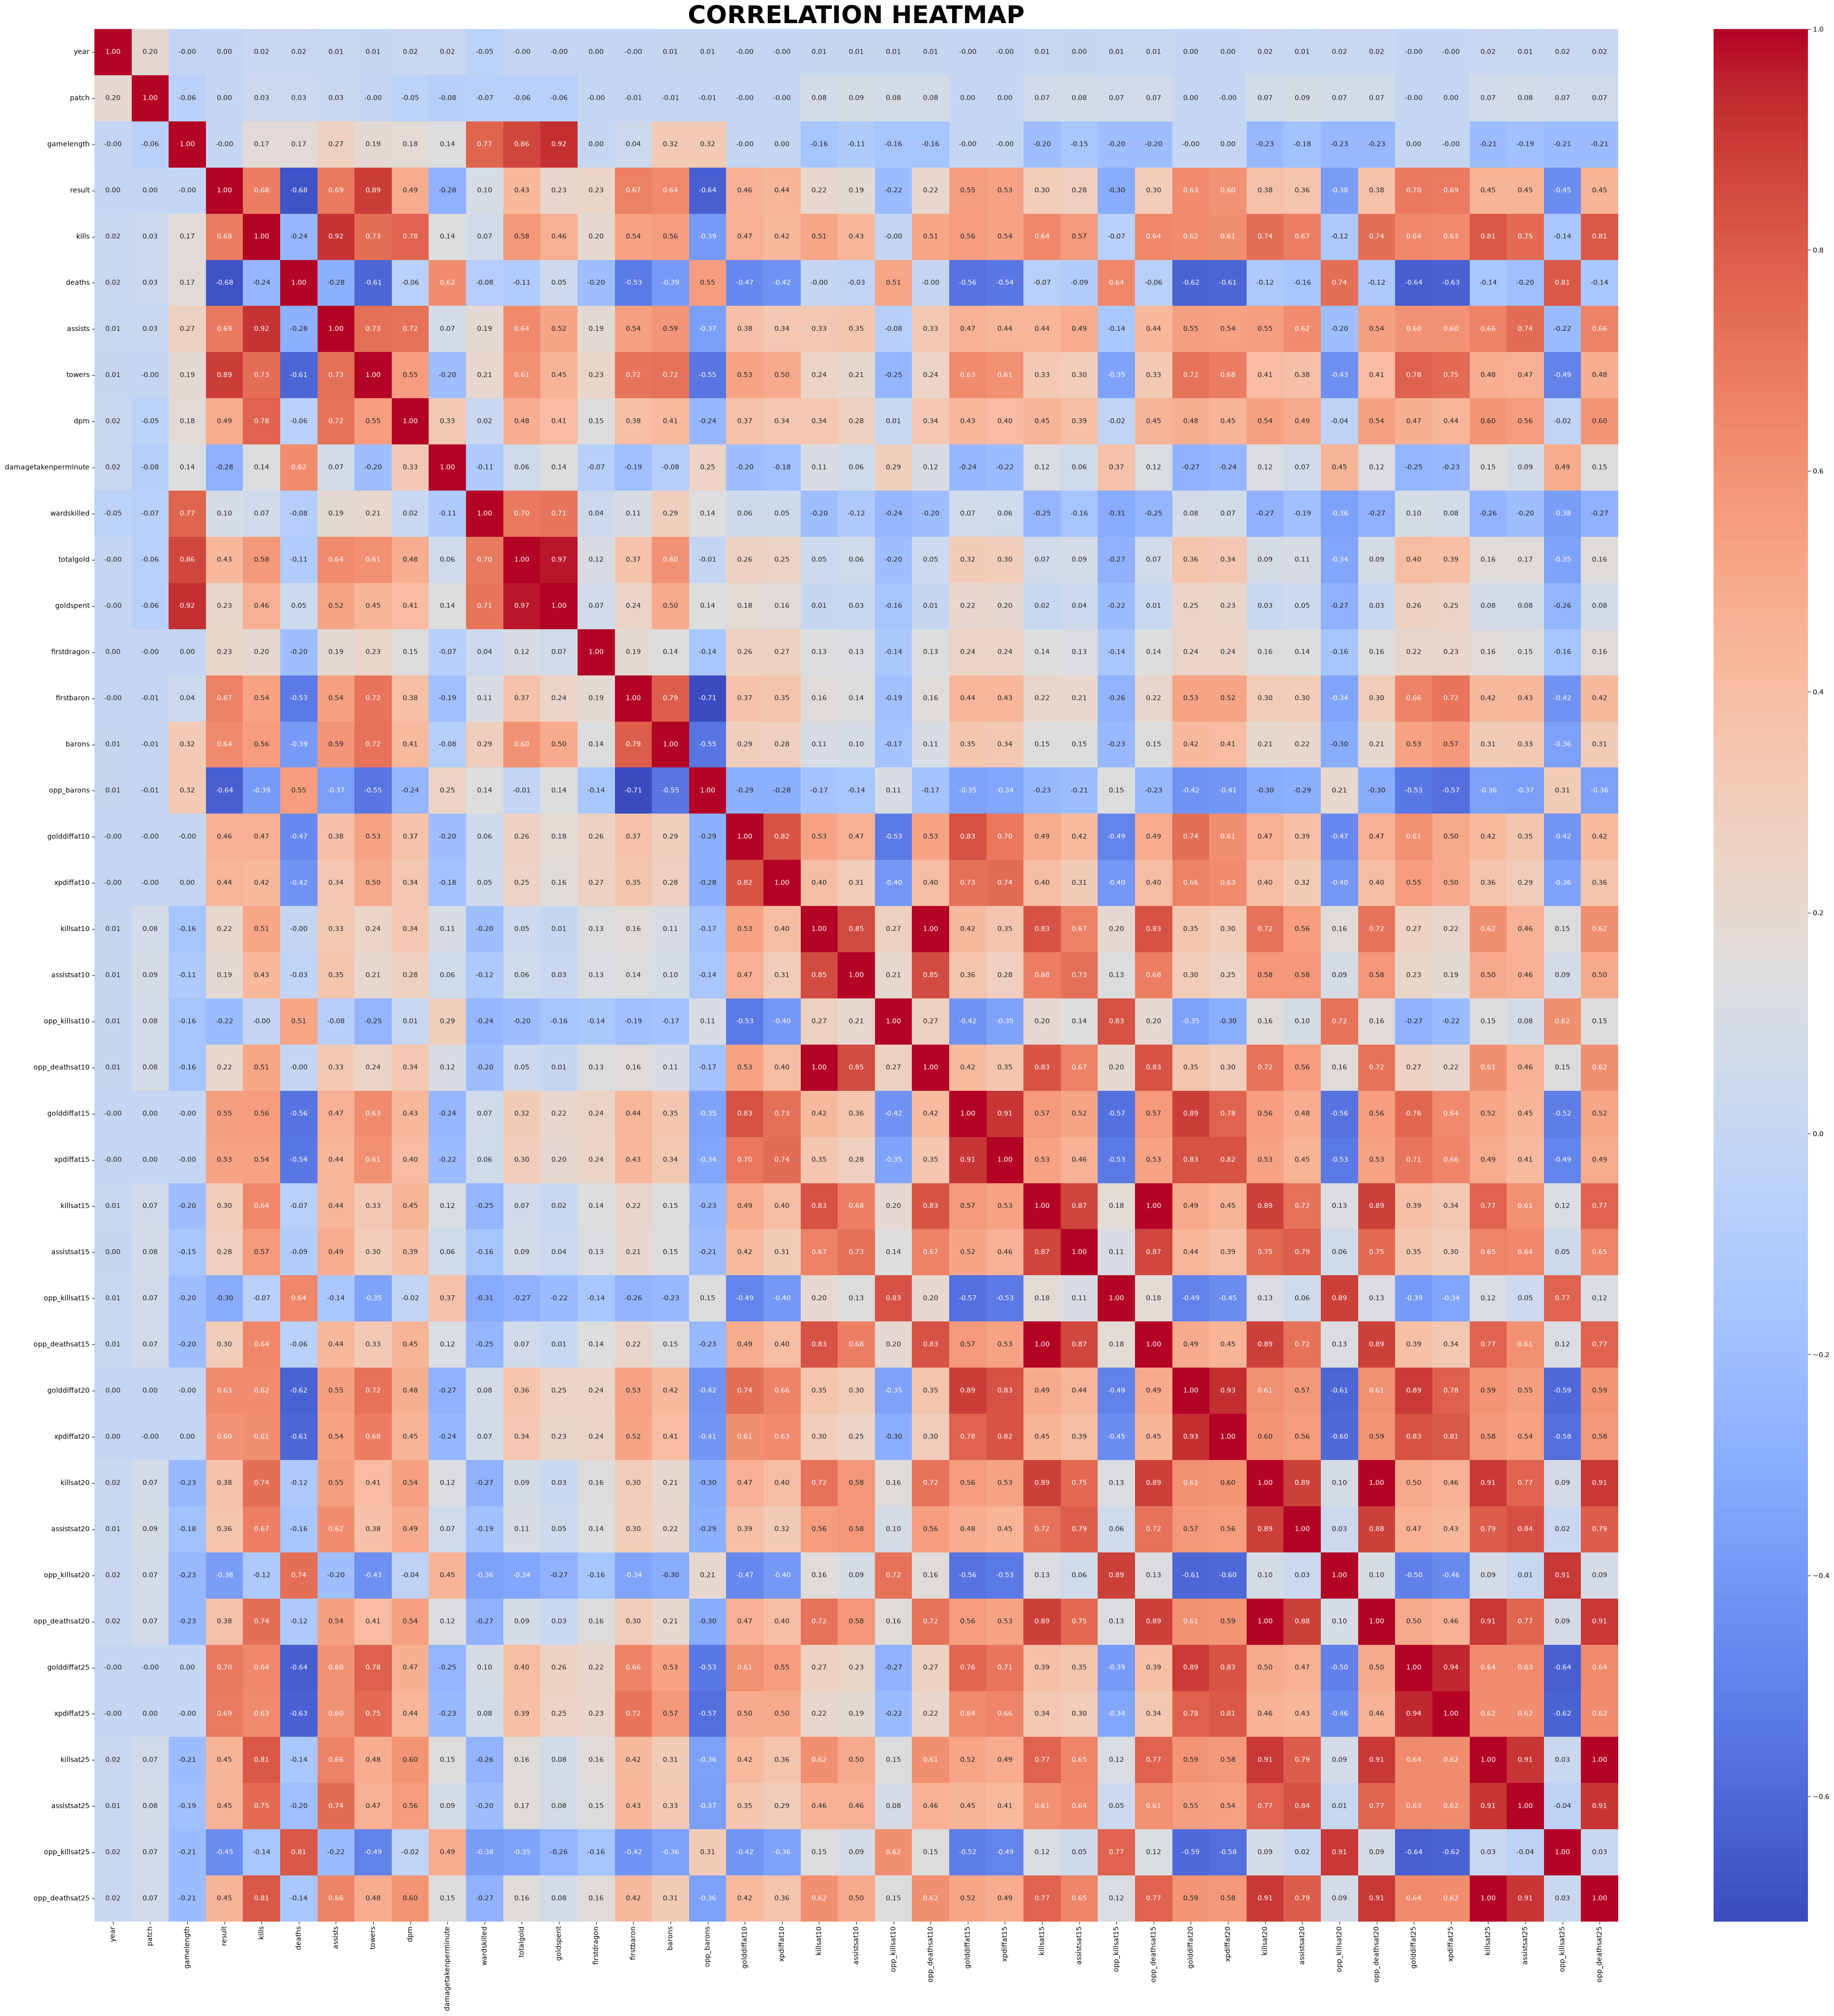

In [18]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(50, 50))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=36, fontweight="bold")
plt.show()